# Chapitre 10 - Exercices 10.6 à 10.11

Ce notebook traite six exercices sur les caches, l'observabilité, l'orchestration et les
retours utilisateurs (cours 2 à 4) :

- **10.6** : le seuil optimal d'un cache sémantique et sa robustesse (calcul + mini-lab) ;
- **10.7** : reproduire et corriger une fuite de données par le cache (mini-lab) ;
- **10.8** : régler une alerte CUSUM : fausses alertes contre délai de détection (calcul + simulation) ;
- **10.9** : chemin critique d'un pipeline et placement d'un garde-fou lent (calcul) ;
- **10.10** : apprendre un score de satisfaction implicite à partir des signaux (mini-lab) ;
- **10.11** : biais de position, puissance statistique et boucle de rétroaction (calcul + simulation).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from aie.plotting import set_style, INDIGO, TEAL, AMBER, ROSE, VIOLET, SKY, SLATE, GRAY, GREEN, COLORS, annotate_bars
from aie import llm
from aie import ch10_architecture as A

set_style()
pd.set_option("display.max_colwidth", 90)
rng = np.random.default_rng(0)
embed = lambda texts: llm.embed(texts, llm.EMBED_MULTI)

## Exercice 10.6 : Le seuil optimal d'un cache sémantique

**Énoncé.** (1) Avec les notations du cours 2 ($h$ taux de succès, $e$ taux d'erreur, $c$ coût
d'un appel, $c_{lk}$ coût de la recherche dans le cache, $c_{err}$ coût d'une mauvaise
réponse), donner la condition pour que le cache sémantique soit rentable. (2) Sur le flux
`A.CACHE_QUERIES`, calculer le seuil optimal $\tau^*$ pour $c_{err} \in \{0, 1, 2, 5, 10, 20\}$
(en unités de $c$, avec $c_{lk} = 0{,}02$). (3) Le taux de succès dépend de l'**ordre**
d'arrivée des requêtes : mesurer sa variabilité sur 200 ordres aléatoires au seuil 0,8.
(4) Que devient la rentabilité si seule une fraction $\rho$ du trafic réel ressemble à ce jeu
(le reste n'a jamais de paraphrase en cache) ?

**Rappels.** Section *Semantic caching* : le cache sémantique n'a de valeur que si le taux
de succès est élevé ; sa recherche vectorielle coûte à chaque requête et une erreur renvoie
la réponse à une autre question. Cours 2 : $\bar c = c_{lk} + (1-h)\,c + e\,c_{err}$.

**Solution.** (1) Le cache est rentable si $\bar c < c$, soit
$$h\,c > c_{lk} + e\,c_{err} :$$
l'économie des succès doit couvrir le coût fixe de la recherche **et** le coût des erreurs.

(2) On évalue $\bar c(\tau)$ sur une grille et on prend l'argmin (ci-dessous).

(4) Sur une fraction $1-\rho$ du trafic, aucune paraphrase n'existe : au mieux pas de succès
(et, pour un seuil bas, de faux succès). En première approximation $h \to \rho h$ et
$e \to \rho e + (1-\rho) e_0$, où $e_0$ est le taux de faux succès sur des requêtes sans
paraphrase. Avec $e_0 \approx 0$ (seuil assez haut), la condition devient
$\rho\,(h c - e\,c_{err}) > c_{lk}$ : il faut $\rho > c_{lk}/(h c - e c_{err})$.

In [2]:
cq = [q for q, _ in A.CACHE_QUERIES]; cg = np.array([g for _, g in A.CACHE_QUERIES])
Ec = embed(cq)
thr = np.linspace(0.5, 1.0, 51)
st = A.pairwise_cache_stats(Ec, cg, thr)
c, c_lk = 1.0, 0.02
rows = []
for c_err in [0, 1, 2, 5, 10, 20]:
    cost = c_lk + (1 - st["hit_rate"]) * c + st["err_rate"] * c_err
    j = int(np.argmin(cost))
    rows.append({"c_err": c_err, "tau*": thr[j], "h": st["hit_rate"][j], "e": st["err_rate"][j], "coût": cost[j],
                 "gain vs sans cache": 1 - cost[j] / c})
opt = pd.DataFrame(rows); opt.round(3)

,c_err,tau*,h,e,coût,gain vs sans cache
0,0,0.50,0.667,0.194,0.353,0.647
1,1,0.54,0.611,0.139,0.548,0.452
2,2,0.54,0.611,0.139,0.687,0.313
3,5,0.82,0.194,0.000,0.826,0.174
4,10,0.82,0.194,0.000,0.826,0.174
5,20,0.82,0.194,0.000,0.826,0.174


**Vérification** (3) : variabilité due à l'ordre, et (4) : rentabilité selon $\rho$.

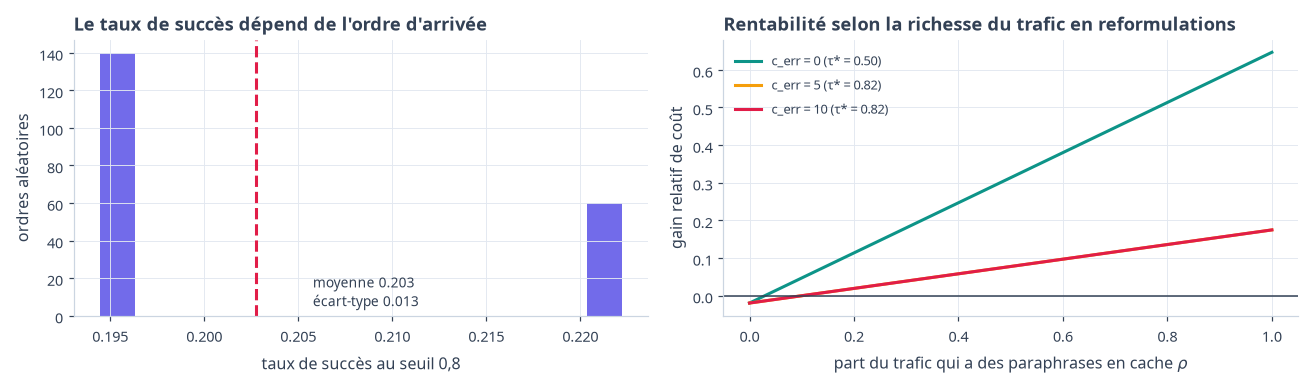

In [3]:
hits = []
for s in range(200):
    perm = np.random.default_rng(s).permutation(len(cq))
    hits.append(A.pairwise_cache_stats(Ec[perm], cg[perm], [0.8])["hit_rate"][0])
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].hist(hits, bins=15, color=INDIGO, alpha=0.8)
ax[0].axvline(np.mean(hits), color=ROSE, ls="--"); ax[0].text(np.mean(hits) + 0.003, 5, f"moyenne {np.mean(hits):.3f}\nécart-type {np.std(hits):.3f}", fontsize=9)
ax[0].set(xlabel="taux de succès au seuil 0,8", ylabel="ordres aléatoires", title="Le taux de succès dépend de l'ordre d'arrivée")
rhos = np.linspace(0, 1, 101)
for c_err, col in [(0, TEAL), (5, AMBER), (10, ROSE)]:
    r = opt[opt.c_err == c_err].iloc[0]
    ax[1].plot(rhos, 1 - (c_lk + (1 - rhos * r.h) * c + rhos * r.e * c_err) / c, color=col, label=f"c_err = {c_err} (τ* = {r['tau*']:.2f})")
ax[1].axhline(0, color=SLATE, lw=1)
ax[1].set(xlabel="part du trafic qui a des paraphrases en cache $\\rho$", ylabel="gain relatif de coût",
          title="Rentabilité selon la richesse du trafic en reformulations")
ax[1].legend(fontsize=8.5); plt.tight_layout(); plt.show()

Le seuil optimal **remonte** quand le coût d'une erreur augmente, et le gain fond. L'ordre
d'arrivée change le taux de succès de quelques points (sur 36 requêtes, chaque succès pèse
près de 3 %) : un réglage fait sur un petit échantillon est fragile. Enfin, quand le trafic
contient peu de reformulations ($\rho$ faible), le gain devient négatif : le coût fixe de la
recherche n'est plus couvert.

> **À retenir.** Cache sémantique rentable $\iff h\,c > c_{lk} + e\,c_{err}$ ; le seuil
> optimal croît avec le coût des erreurs, et tout dépend de la part réelle de reformulations.